# Candy Model
### Training ML model for the detacting the candyy


**Downloading the Dataset**

In [8]:
!pip install -q ultralytics roboflow pyyaml opencv-python matplotlib

In [9]:
import os
import yaml
import torch
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
from google.colab import files

print("All libraries imported successfully!")

All libraries imported successfully!


**Trainning the Model**

In [10]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    raise RuntimeError(
        "GPU not available! Go to Runtime > Change runtime type > T4 GPU."
    )

PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [12]:
# Roboflow project details
workspace_name = "workenv-dayet"
project_name = "candy-g6wfi"
version_number = 4

project = rf.workspace(workspace_name).project(project_name)

# Download YOLOv8 dataset
dataset = project.version(version_number).download("yolov8")

DATASET_PATH = dataset.location

print("Dataset downloaded successfully!")
print("Dataset location:", DATASET_PATH)

loading Roboflow workspace...
loading Roboflow project...
Dataset downloaded successfully!
Dataset location: /content/Candy-4


In [13]:
DATA_YAML = os.path.join(DATASET_PATH, "data.yaml")

assert os.path.exists(DATA_YAML), "data.yaml not found!"

with open(DATA_YAML, "r") as file:
    data = yaml.safe_load(file)

print("Dataset Configuration")
print("======================")

print("Classes:", data["names"])
print("Number of classes:", data["nc"])

print("Training:", data["train"])
print("Validation:", data["val"])
print("Testing:", data.get("test"))

Dataset Configuration
Classes: ['Bounty', 'Dare_caramel', 'Dare_cocoa', 'MMs_peanut', 'MMs_regular', 'Mars', 'Twix_caramel', 'Twix_clasic', 'Twix_white', 'airheads', 'eugenia', 'gummy_worms', 'milky_way', 'nerds', 'skittles', 'snickers', 'snickers_creamy', 'starbust', 'three_musketeers', 'twizzlers']
Number of classes: 20
Training: ../train/images
Validation: ../valid/images
Testing: ../test/images


In [14]:
# Set absolute dataset path
data["path"] = DATASET_PATH

data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

# Check class configuration
assert data["nc"] == 20
assert len(data["names"]) == 20

# Save corrected configuration
with open(DATA_YAML, "w") as file:
    yaml.safe_dump(data, file, sort_keys=False)

print("Dataset YAML configured successfully!")

Dataset YAML configured successfully!


In [15]:
splits = ["train", "valid", "test"]

for split in splits:

    image_dir = Path(DATASET_PATH) / split / "images"
    label_dir = Path(DATASET_PATH) / split / "labels"

    assert image_dir.exists(), f"{split} images folder missing!"
    assert label_dir.exists(), f"{split} labels folder missing!"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
    ]

    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("Labels:", len(labels))

    assert len(images) > 0, f"No images in {split}!"

print("\nDataset validation completed!")


TRAIN DATASET
Images: 348
Labels: 348

VALID DATASET
Images: 34
Labels: 34

TEST DATASET
Images: 16
Labels: 16

Dataset validation completed!


In [16]:
image_dir = Path(DATASET_PATH) / "train/images"

image_files = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

samples = random.sample(image_files, min(9, len(image_files)))

plt.figure(figsize=(15, 12))

for i, image_path in enumerate(samples):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

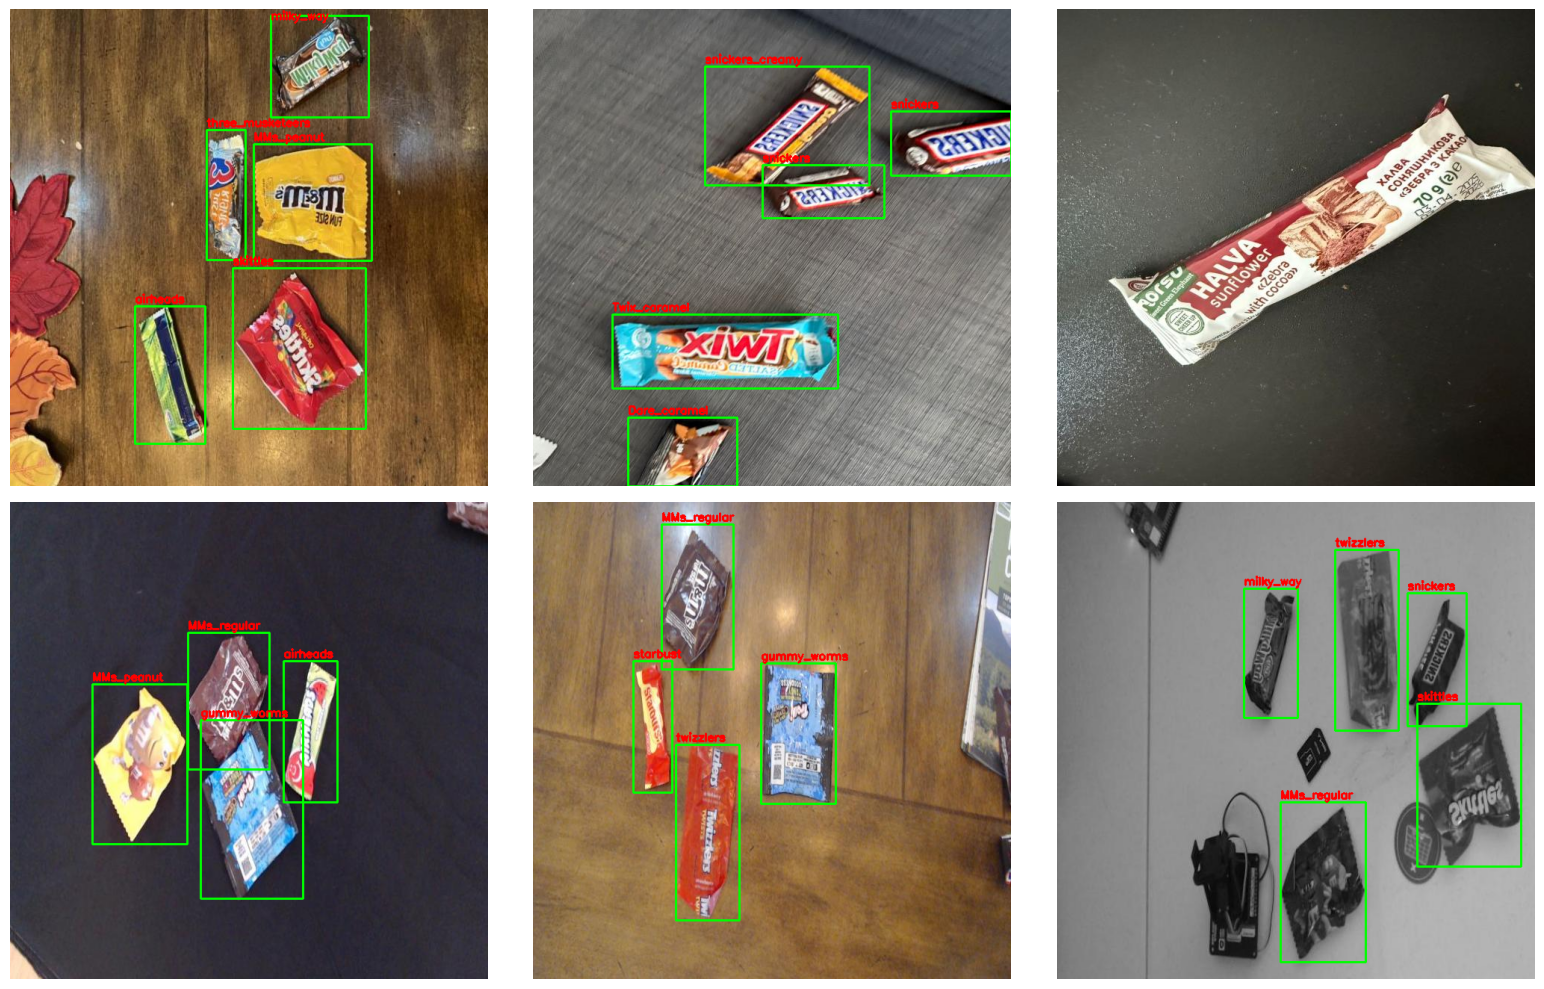

In [17]:
image_dir = Path(DATASET_PATH) / "train/images"
label_dir = Path(DATASET_PATH) / "train/labels"

class_names = data["names"]

samples = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(16, 10))

for i, image_path in enumerate(samples):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w, _ = image.shape

    label_path = label_dir / f"{image_path.stem}.txt"

    if label_path.exists():

        with open(label_path, "r") as file:
            annotations = file.readlines()

        for annotation in annotations:

            values = annotation.strip().split()

            if len(values) != 5:
                continue

            cls, x, y, bw, bh = map(float, values)

            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                image,
                class_names[int(cls)],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
model = YOLO("yolov8n.pt")

print("YOLOv8 Nano model loaded!")

YOLOv8 Nano model loaded!


In [19]:
results = model.train(

    # Dataset
    data=DATA_YAML,

    # Training settings
    epochs=100,
    imgsz=640,
    batch=16,

    # GPU settings
    device=0,
    workers=2,

    # Optimizer
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,

    # Learning rate scheduler
    cos_lr=True,

    # Early stopping
    patience=20,

    # Augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=10,

    # Saving
    save=True,
    save_period=10,
    plots=True,

    # Output directory
    project="/content/Candy-Training",
    name="candy-yolov8n",
    exist_ok=True,

    verbose=True
)

print("Training completed successfully!")

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Candy-4/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=candy-yolov8n, nbs=64, nms=None, opset=None, optimize=False, o

In [20]:
BEST_MODEL = (
    "/content/Candy-Training/candy-yolov8n/weights/best.pt"
)

assert os.path.exists(BEST_MODEL), "Best model weights not found!"

best_model = YOLO(BEST_MODEL)

print("Best model loaded successfully!")

Best model loaded successfully!


In [21]:
metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("\n========== TEST RESULTS ==========")

print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")

print("==================================")

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,324 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1669.2±315.5 MB/s, size: 65.1 KB)
val: Scanning /content/Candy-4/test/labels... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 1.9Kit/s 0.0s
val: New cache created: /content/Candy-4/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.3it/s 0.3s
                   all         16         68      0.741      0.917      0.928      0.777
                Bounty          1          1      0.567          1      0.995      0.895
          Dare_caramel          1          1      0.871          1      0.995      0.497
            Dare_cocoa          1          1          1          0          0          0
            MMs_peanut          4          4      0.828          1      0.995      0.928
  

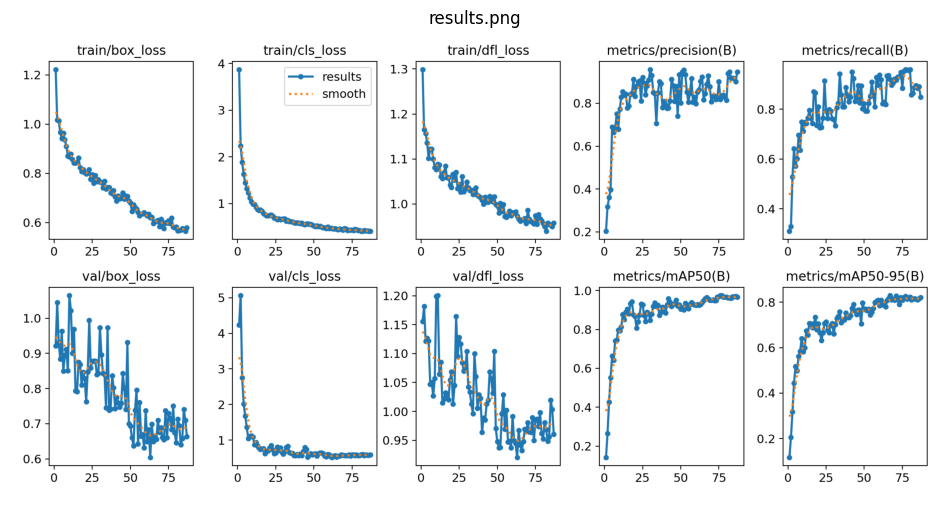

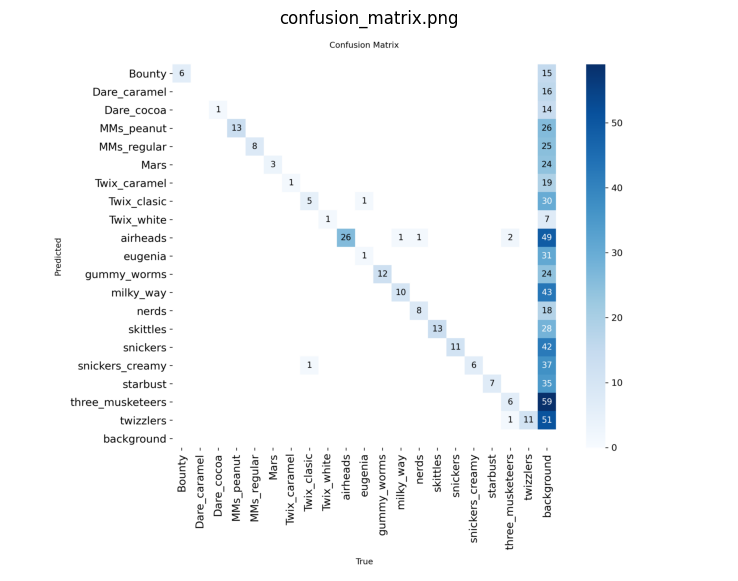

In [22]:
RESULTS_DIR = "/content/Candy-Training/candy-yolov8n"

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]

for filename in plot_files:

    path = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(path):

        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 7))
        plt.imshow(image)
        plt.title(filename)
        plt.axis("off")
        plt.show()

In [ ]:
uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Image uploaded:", image_path)

In [ ]:
predictions = best_model.predict(
    source=image_path,
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=0,
    save=True,
    show_labels=True,
    show_conf=True
)

print("Candy detection completed!")

In [ ]:
result_image = predictions[0].plot()

plt.figure(figsize=(14, 9))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.title("Candy Detection Results")
plt.axis("off")
plt.show()

In [ ]:
from collections import Counter

result = predictions[0]

detected_classes = result.boxes.cls.cpu().numpy().astype(int)

counts = Counter(detected_classes)

print("\n========== CANDY COUNT ==========")

for class_id, count in sorted(counts.items()):

    print(f"{data['names'][class_id]}: {count}")

print("--------------------------------")
print("Total candies detected:", len(detected_classes))
print("================================")

In [ ]:
onnx_path = best_model.export(
    format="onnx",
    imgsz=640,
    simplify=True
)

print("ONNX exported:", onnx_path)

In [ ]:
files.download(BEST_MODEL)